<a href="https://colab.research.google.com/github/Anishamalar/Weather-prediction-using-python/blob/main/Machine_learning_final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**WEATHER PREDICTION USING MACHINE LEARNING AND PYTHON**

- ANISHA SUNDARAM –36060415​

To create a weather prediction model using Python and machine learning in Google Colab, we'll follow these steps:

Load and Explore the Data: Understand the dataset and preprocess it.
Feature Engineering: Prepare the data for modeling.
Train-Test Split: Divide the data into training and testing sets.
Model Selection: Choose a machine learning algorithm.
Training the Model: Train the chosen model on the training set.
Evaluation: Evaluate the model's performance on the test set.
Prediction: Make predictions using the trained model.

**1. Load and Explore the Data**

    First, we need to load the dataset and take a look at its structure. Here is the code to do that:

In [ ]:
import pandas as pd

# Load the dataset
file_path = 'Weather_prediction.csv'
df = pd.read_csv(file_path)

# Display the first few rows of the dataframe
df.head()


,DATE,MONTH,BASEL_cloud_cover,BASEL_humidity,BASEL_pressure,BASEL_global_radiation,BASEL_precipitation,BASEL_sunshine,BASEL_temp_mean,BASEL_temp_min,...,STOCKHOLM_temp_min,STOCKHOLM_temp_max,TOURS_wind_speed,TOURS_humidity,TOURS_pressure,TOURS_global_radiation,TOURS_precipitation,TOURS_temp_mean,TOURS_temp_min,TOURS_temp_max
0,20000101,1,8,0.89,1.0286,0.20,0.03,0.0,2.9,1.6,...,-9.3,0.7,1.6,0.97,1.0275,0.25,0.04,8.5,7.2,9.8
1,20000102,1,8,0.87,1.0318,0.25,0.00,0.0,3.6,2.7,...,0.5,2.0,2.0,0.99,1.0293,0.17,0.16,7.9,6.6,9.2
2,20000103,1,5,0.81,1.0314,0.50,0.00,3.7,2.2,0.1,...,-1.0,2.8,3.4,0.91,1.0267,0.27,0.00,8.1,6.6,9.6
3,20000104,1,7,0.79,1.0262,0.63,0.35,6.9,3.9,0.5,...,2.5,4.6,4.9,0.95,1.0222,0.11,0.44,8.6,6.4,10.8
4,20000105,1,5,0.90,1.0246,0.51,0.07,3.7,6.0,3.8,...,-1.8,2.9,3.6,0.95,1.0209,0.39,0.04,8.0,6.4,9.5


In [ ]:
print(df.tail())

          DATE  MONTH  BASEL_cloud_cover  BASEL_humidity  BASEL_pressure  \
3649  20091228     12                  7            0.82          1.0084   
3650  20091229     12                  7            0.92          1.0028   
3651  20091230     12                  8            0.92          0.9979   
3652  20091231     12                  7            0.93          0.9958   
3653  20100101      1                  8            0.93          0.9965   

      BASEL_global_radiation  BASEL_precipitation  BASEL_sunshine  \
3649                    0.28                 0.42             0.3   
3650                    0.22                 1.68             0.2   
3651                    0.07                 1.54             0.0   
3652                    0.17                 0.57             0.1   
3653                    0.08                 0.56             0.0   

      BASEL_temp_mean  BASEL_temp_min  ...  STOCKHOLM_temp_min  \
3649              3.2             1.0  ...                -2.7

In [ ]:
print(df.info(verbose=True))
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3654 entries, 0 to 3653
Data columns (total 165 columns):
 #    Column                       Dtype  
---   ------                       -----  
 0    DATE                         int64  
 1    MONTH                        int64  
 2    BASEL_cloud_cover            int64  
 3    BASEL_humidity               float64
 4    BASEL_pressure               float64
 5    BASEL_global_radiation       float64
 6    BASEL_precipitation          float64
 7    BASEL_sunshine               float64
 8    BASEL_temp_mean              float64
 9    BASEL_temp_min               float64
 10   BASEL_temp_max               float64
 11   BUDAPEST_cloud_cover         int64  
 12   BUDAPEST_humidity            float64
 13   BUDAPEST_pressure            float64
 14   BUDAPEST_global_radiation    float64
 15   BUDAPEST_precipitation       float64
 16   BUDAPEST_sunshine            float64
 17   BUDAPEST_temp_mean           float64
 18   BUDAPEST_temp_max         

**2. Feature Engineering**

    Next, we need to handle missing values, and perform any other necessary preprocessing steps.

In [ ]:
missing_values = df.isnull().sum()
df = df.dropna()
print("\nMissing values in each column")
print(missing_values)


Missing values in each column
DATE                      0
MONTH                     0
BASEL_cloud_cover         0
BASEL_humidity            0
BASEL_pressure            0
                         ..
TOURS_global_radiation    0
TOURS_precipitation       0
TOURS_temp_mean           0
TOURS_temp_min            0
TOURS_temp_max            0
Length: 165, dtype: int64


In [ ]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

In [ ]:
#Convert to pandas date format
df['DATE'] = pd.to_datetime(df['DATE'], format='%Y%m%d')
print(df.head())

        DATE  MONTH  BASEL_cloud_cover  BASEL_humidity  BASEL_pressure  \
0 2000-01-01      1                  8            0.89          1.0286   
1 2000-01-02      1                  8            0.87          1.0318   
2 2000-01-03      1                  5            0.81          1.0314   
3 2000-01-04      1                  7            0.79          1.0262   
4 2000-01-05      1                  5            0.90          1.0246   

   BASEL_global_radiation  BASEL_precipitation  BASEL_sunshine  \
0                    0.20                 0.03             0.0   
1                    0.25                 0.00             0.0   
2                    0.50                 0.00             3.7   
3                    0.63                 0.35             6.9   
4                    0.51                 0.07             3.7   

   BASEL_temp_mean  BASEL_temp_min  ...  STOCKHOLM_temp_min  \
0              2.9             1.6  ...                -9.3   
1              3.6             2

**3. Train-Test Split**

    We will split the data into training and testing sets.

In [ ]:
# Display the column names to identify the correct target column
df.columns

Index(['DATE', 'MONTH', 'BASEL_cloud_cover', 'BASEL_humidity',
       'BASEL_pressure', 'BASEL_global_radiation', 'BASEL_precipitation',
       'BASEL_sunshine', 'BASEL_temp_mean', 'BASEL_temp_min',
       ...
       'STOCKHOLM_temp_min', 'STOCKHOLM_temp_max', 'TOURS_wind_speed',
       'TOURS_humidity', 'TOURS_pressure', 'TOURS_global_radiation',
       'TOURS_precipitation', 'TOURS_temp_mean', 'TOURS_temp_min',
       'TOURS_temp_max'],
      dtype='object', length=165)

We select here the feature column as BASEL that is SWITZERLAND and calculate only for the country SWITZERLAND.

In [ ]:
from sklearn.model_selection import train_test_split

# Define features and target variable
feature_columns = ['BASEL_cloud_cover', 'BASEL_humidity', 'BASEL_pressure',
                   'BASEL_global_radiation', 'BASEL_sunshine',
                   'BASEL_temp_mean', 'BASEL_temp_min', 'BASEL_temp_max']

X = df[feature_columns]  # Selecting specific columns for features

y = df['BASEL_precipitation']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
# Display the train and test splits
print("Training Features (X_train):")
print(X_train.head())

print("\nTesting Features (X_test):")
print(X_test.head())

print("\nTraining Labels (y_train):")
print(y_train.head())

print("\nTesting Labels (y_test):")
print(y_test.head())


Training Features (X_train):
      BASEL_cloud_cover  BASEL_humidity  BASEL_pressure  \
2788                  7            0.80          1.0092   
2992                  7            0.63          1.0021   
2287                  4            0.70          1.0162   
1414                  6            0.80          1.0180   
2865                  1            0.79          1.0275   

      BASEL_global_radiation  BASEL_sunshine  BASEL_temp_mean  BASEL_temp_min  \
2788                    1.07             0.3             15.3            13.8   
2992                    1.16             3.3              9.2             6.4   
2287                    1.75             5.0              3.7            -0.5   
1414                    0.75             3.6              7.7             3.1   
2865                    1.01             8.6              5.2             0.9   

      BASEL_temp_max  
2788            17.9  
2992            12.8  
2287             8.6  
1414            12.6  
2865          

4. Model Selection
**MODEL 1:**
We will use a Linear Regression for this example.



5. Training the Model

Train the model using the training data.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score
model = LinearRegression()

# Train the model on the training data
model.fit(X_train, y_train)

# Make predictions using the testing data
y_pred = model.predict(X_test)

# Evaluate the model LINEAR REGRESSION
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')
print("Mean Absolute Error (MAE):", mae)
print(f'R-squared: {r2}'  )


Mean Squared Error: 0.231536442480046
Mean Absolute Error (MAE): 0.28089049971380253
R-squared: 0.20631959880251716


6. Prediction

Make predictions using the trained model.
The model's performance on the test set is quite good, with the following metrics:

Mean Squared Error (MSE):  0.231
R-squared (R²) Score:  0.206

In [ ]:
from sklearn.metrics import r2_score

# Fit the model on the training data
model.fit(X_train, y_train)

# Calculate R-squared (R2) scores
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

# train_score = r2_score(y_train, model.predict(X_train))
# test_score = r2_score(y_test, model.predict(X_test))

print(f"Training R2 score: {train_score}")
print(f"Testing R2 score: {test_score}")

Training R2 score: 0.21274577654726623
Testing R2 score: 0.20631959880251716


In [ ]:
y_pred = model.predict(X_test)

# Print the actual and predicted precipitation values for comparison
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results.head(30))

      Actual  Predicted
1313    0.00   0.078080
1674    0.00   0.043695
229     1.00   0.372807
3509    3.74   0.593170
2222    0.00   0.018550
807     0.06   0.240988
761     0.00   0.216747
2656    0.00  -0.151075
736     0.00  -0.178491
2972    0.41   0.117077
1786    0.05   0.066896
3176    0.27   0.539496
1872    0.00   0.354163
32      0.99   0.395413
2798    0.22   0.466543
1436    0.00  -0.273905
2973    0.16   0.338562
1867    0.00  -0.126589
2740    0.78   0.582370
3032    0.00   0.463830
790     1.64   0.361005
3399    0.00   0.020564
3173    0.00   0.239644
3604    0.00   0.445354
1532    0.40   0.286021
2254    5.36   0.782874
443     0.36   0.298812
2348    0.00  -0.118764
402     0.00   0.256339
93      0.00   0.551440


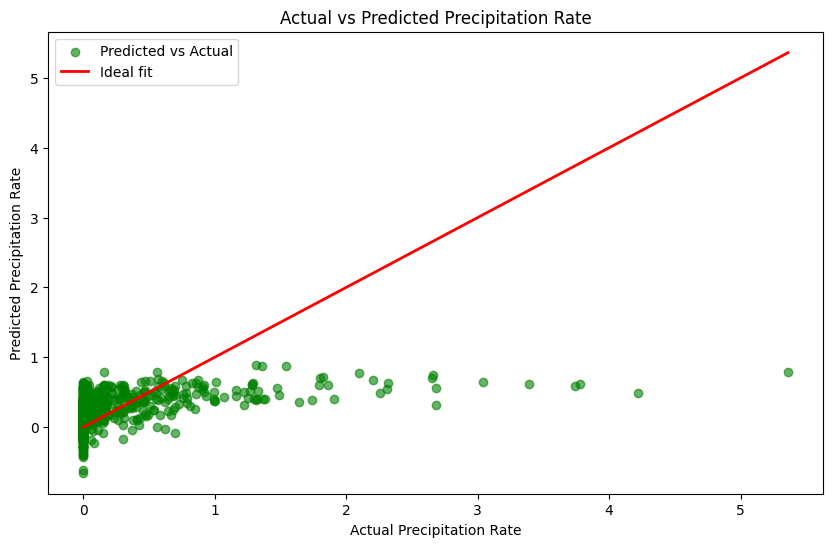

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='green', label='Predicted vs Actual', alpha=0.6)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='-', linewidth=2, label='Ideal fit')
plt.xlabel('Actual Precipitation Rate')
plt.ylabel('Predicted Precipitation Rate')
plt.title('Actual vs Predicted Precipitation Rate')
plt.legend()
plt.show()

**MODEL 2:**
We will use Random forest regression model.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
# Initialize the RandomForestRegressor model
model = RandomForestRegressor()

# Train the model
model.fit(X_train, y_train)
# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate accuracy
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nMean Squared Error: {mse}")
print("Mean Absolute Error (MAE):", mae)
print(f"R-squared Score: {r2}")


Mean Squared Error: 0.2107484323119015
Mean Absolute Error (MAE): 0.23550752393980848
R-squared Score: 0.2775785162913793


In [ ]:
from sklearn.metrics import r2_score

# Fit the model on the training data
model.fit(X_train, y_train)

# Calculate R-squared (R2) scores
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

# train_score = r2_score(y_train, model.predict(X_train))
# test_score = r2_score(y_test, model.predict(X_test))

print(f"Training R2 score: {train_score}")
print(f"Testing R2 score: {test_score}")

Training R2 score: 0.9007386321408762
Testing R2 score: 0.26557914406467464


In [ ]:
# Print the actual and predicted precipitation values for comparison
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results.head(30))

      Actual  Predicted
1313    0.00     0.0097
1674    0.00     0.0298
229     1.00     0.3978
3509    3.74     1.2868
2222    0.00     0.0597
807     0.06     0.2275
761     0.00     0.1883
2656    0.00     0.0000
736     0.00     0.0247
2972    0.41     0.0807
1786    0.05     0.0076
3176    0.27     0.6558
1872    0.00     0.1736
32      0.99     0.3547
2798    0.22     0.2120
1436    0.00     0.0005
2973    0.16     0.3834
1867    0.00     0.0274
2740    0.78     0.4550
3032    0.00     0.2956
790     1.64     0.3623
3399    0.00     0.0027
3173    0.00     0.0475
3604    0.00     0.6682
1532    0.40     0.3016
2254    5.36     0.9506
443     0.36     0.2162
2348    0.00     0.0130
402     0.00     0.0908
93      0.00     0.1250


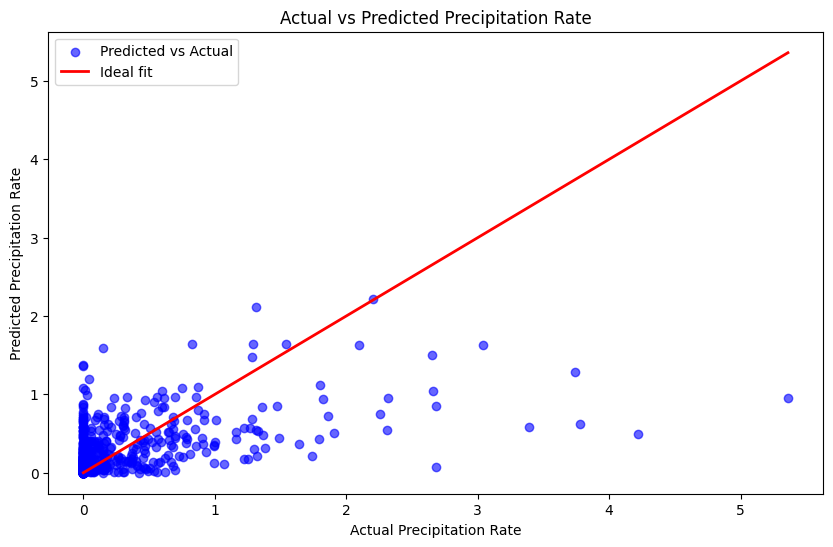

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', label='Predicted vs Actual', alpha=0.6)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='-', linewidth=2, label='Ideal fit')
plt.xlabel('Actual Precipitation Rate')
plt.ylabel('Predicted Precipitation Rate')
plt.title('Actual vs Predicted Precipitation Rate')
plt.legend()
plt.show()

**MODEL 3:**
We will use XGBoost model.

In [ ]:
import xgboost as xgb
xgb_model = xgb.XGBRegressor()
# Train the model on the training data
xgb_model.fit(X_train, y_train)
# Make predictions using the testing data
y_pred = xgb_model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'Mean Absolute Error (MAE): {mae}')
print(f'R-squared: {r2}')

Mean Squared Error: 0.25565565288006054
Mean Absolute Error (MAE): 0.2541040177904923
R-squared: 0.1236417085239716


In [ ]:
# Calculate R-squared (R2) scores
train_score = xgb_model.score(X_train, y_train)
test_score = xgb_model.score(X_test, y_test)

print(f"Training R2 score: {train_score}")
print(f"Testing R2 score: {test_score}")

Training R2 score: 0.9789804141411345
Testing R2 score: 0.1236417085239716


In [ ]:
# Print the actual and predicted precipitation values for comparison
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results.head(30))

      Actual  Predicted
1313    0.00   0.063259
1674    0.00   0.042197
229     1.00   0.195604
3509    3.74   0.420195
2222    0.00   0.045743
807     0.06   0.202382
761     0.00   0.227501
2656    0.00  -0.016308
736     0.00  -0.005133
2972    0.41   0.039399
1786    0.05   0.006178
3176    0.27   0.628500
1872    0.00   0.368274
32      0.99   0.227089
2798    0.22   0.207098
1436    0.00  -0.007570
2973    0.16   0.404490
1867    0.00  -0.002749
2740    0.78   0.370476
3032    0.00   0.067959
790     1.64   0.358049
3399    0.00  -0.012610
3173    0.00  -0.018855
3604    0.00   0.711460
1532    0.40   0.181507
2254    5.36   0.771945
443     0.36   0.104851
2348    0.00  -0.013898
402     0.00   0.156921
93      0.00   0.036050


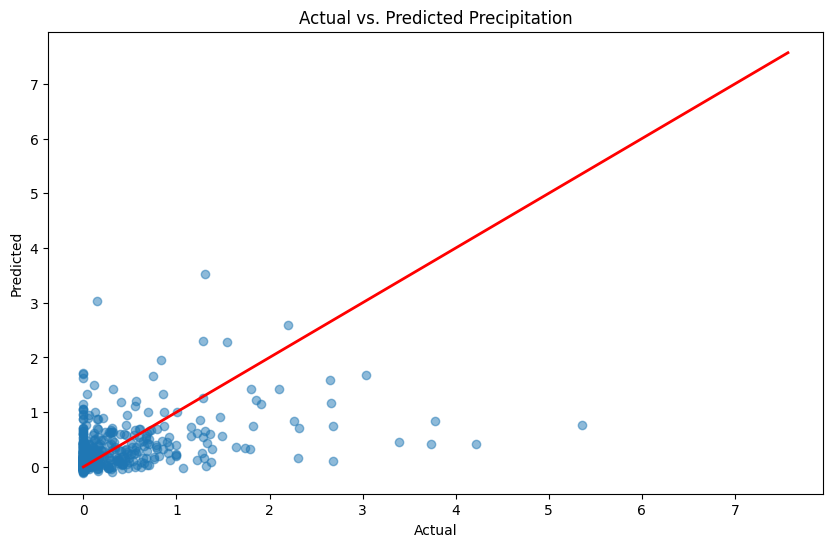

In [ ]:
# Plotting the results
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='-', linewidth=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs. Predicted Precipitation')
plt.show()

**CONCLUSION**

Linear Regression performs the best among the three models in terms of generalization, as indicated by its similar R² scores on both the training and testing data. This suggests it has the most stable performance across different datasets, although the overall performance (R² = 0.21) is still relatively low.Random Forest and XGBoost exhibit overfitting, with high training scores but much lower testing scores. Between these two, Random Forest performs slightly better in terms of testing R² compared to XGBoost, but neither is ideal due to their overfitting issues.